# 01a. Exploratory Data Analysis: Target

**Owner:** Member A (Logistic Regression)
**Project:** Predicting district-level dengue outbreaks in Sri Lanka two weeks ahead

This notebook studies the quantity we are trying to predict: weekly dengue cases and the outbreak label built from them. Feature analysis is in `01b_eda_features.ipynb`.

**Questions answered here**

1. How are weekly case counts distributed, and what does that imply for preprocessing?
2. How do cases vary over time, across the year and between districts?
3. How strongly does this week's count depend on recent weeks?
4. What does the outbreak label look like under the agreed definition, and how balanced is each split?
5. How sensitive is the label to the way an outbreak is defined?

**Rule against test-set snooping.** Distributions and relationships are measured on the training years (2007 to 2020) only. The full 2006 to 2025 series is shown once for context, and class balance is reported for every split because it determines which metrics are meaningful.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so the shared `src` modules work from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, viz
from src.data_loader import load_raw, load_dataset, split_summary, year_to_split

viz.set_style()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 120)

## 0. Load the data

`load_dataset()` in `src/data_loader.py` reads the raw CSV, fits the outbreak thresholds on training years, builds the two-week-ahead target and assigns the temporal split. Rows are removed in three cases:

* **2006**, which contains a single week
* the **final two weeks** of each district, which have no future outcome
* an **embargo** of two weeks at each split boundary, so no training row is labelled with a validation or test outcome

In [2]:
raw = load_raw()
df, thresholds = load_dataset()

train = df[df["split"] == "train"]
raw_train = raw[raw["year"].between(*config.TRAIN_YEARS)]

print(f"Raw data:        {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Modelling data:  {df.shape[0]:,} rows ({raw.shape[0] - df.shape[0]} removed)")
print(f"Training rows:   {train.shape[0]:,}")
print(f"Districts:       {df[config.DISTRICT_COL].nunique()}")

Raw data:        24,775 rows x 28 columns
Modelling data:  24,600 rows (175 removed)
Training rows:   18,200
Districts:       25


## 1. Distribution of weekly cases

The outbreak label is built from `cases`, so its shape matters for both the label and any feature derived from past cases.

In [3]:
cases = raw_train[config.CASES_COL]
summary = pd.Series({
    "mean": cases.mean(),
    "median": cases.median(),
    "90th percentile": cases.quantile(0.90),
    "99th percentile": cases.quantile(0.99),
    "max": cases.max(),
    "skewness": cases.skew(),
    "skewness of log(1 + cases)": np.log1p(cases).skew(),
    "zero-case weeks (%)": (cases == 0).mean() * 100,
}).round(2)
summary.to_frame("training years")

,training years
mean,31.60
median,8.00
90th percentile,73.00
99th percentile,383.51
max,2631.00
skewness,10.50
skewness of log(1 + cases),0.31
zero-case weeks (%),15.00


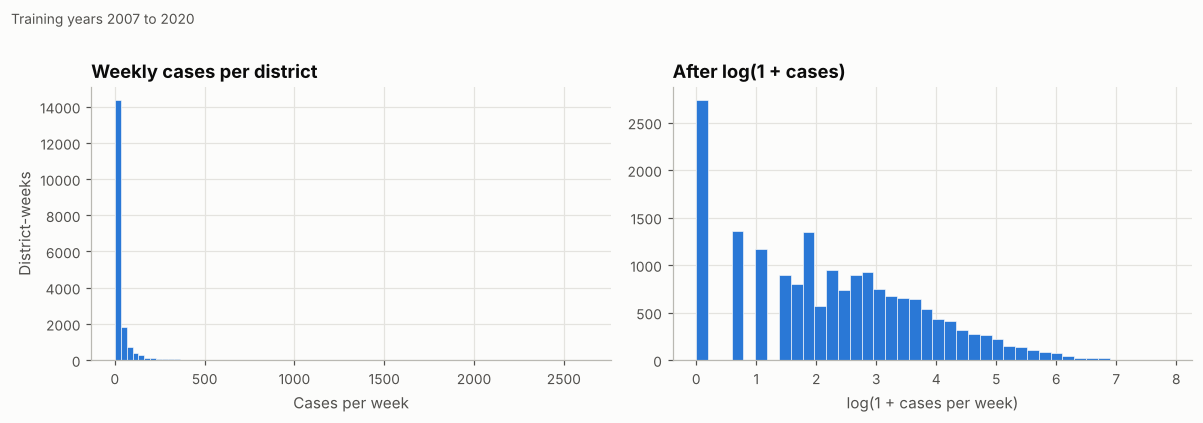

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].hist(cases, bins=80, color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=0.4)
axes[0].set_title("Weekly cases per district")
axes[0].set_xlabel("Cases per week")
axes[0].set_ylabel("District-weeks")

axes[1].hist(np.log1p(cases), bins=40, color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=0.4)
axes[1].set_title("After log(1 + cases)")
axes[1].set_xlabel("log(1 + cases per week)")

fig.suptitle("Training years 2007 to 2020", x=0.01, ha="left", fontsize=9, color=viz.TEXT_MUTED, y=1.0)
fig.tight_layout()
viz.save(fig, "eda_a_01_case_distribution")
plt.show()

**Finding.** Weekly cases are extremely right-skewed (skewness about 10.5): the median district-week in the training years has 8 cases, yet the tail runs past 2,600, and 15% of district-weeks record no cases at all. A log(1 + x) transform brings the skewness close to zero.

**Implication.** Any feature built from past case counts should be log-transformed before it reaches Logistic Regression, whose linear decision boundary is distorted by a handful of extreme values. Random Forest splits on rank order and does not need this.

## 2. National time series (full period, for context only)

This is the only plot that shows validation and test years. It is included so the split boundaries can be read against the history of the epidemic.

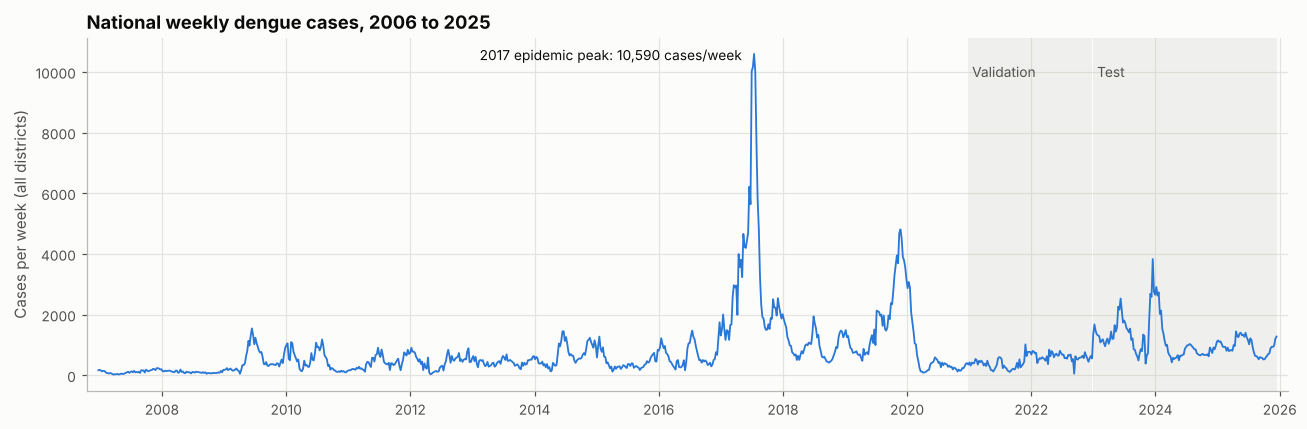

In [5]:
national = raw.groupby(config.DATE_COL)[config.CASES_COL].sum()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(national.index, national.values, color=viz.BLUE, linewidth=1.2)

bands = [("Validation", config.VAL_YEARS), ("Test", config.TEST_YEARS)]
for label, (start, end) in bands:
    mask = raw["year"].between(start, end)
    lo, hi = raw.loc[mask, config.DATE_COL].min(), raw.loc[mask, config.DATE_COL].max()
    ax.axvspan(lo, hi, color=viz.NEUTRAL, alpha=0.18, linewidth=0)
    ax.text(lo, national.max() * 0.97, f" {label}", va="top", fontsize=9, color=viz.TEXT_MUTED)

peak_date = national.idxmax()
ax.annotate(f"2017 epidemic peak: {national.max():,.0f} cases/week",
            xy=(peak_date, national.max()), xytext=(-8, -4), textcoords="offset points",
            ha="right", fontsize=9, color=viz.TEXT)
ax.set_title("National weekly dengue cases, 2006 to 2025")
ax.set_ylabel("Cases per week (all districts)")
ax.margins(x=0.01)
fig.tight_layout()
viz.save(fig, "eda_a_02_national_time_series")
plt.show()

In [6]:
annual = raw.groupby("year").agg(cases=(config.CASES_COL, "sum"))
annual["split"] = year_to_split(pd.Series(annual.index, index=annual.index))
population = raw.groupby(["year", config.DISTRICT_COL])["population"].first().groupby("year").sum()
annual["cases per 100,000"] = (annual["cases"] / population * 1e5).round(0)
annual.T

year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
cases,167,6019,5536,26731,25006,21647,23527,22387,35314,22313,35192,174687,51321,94780,32222,20213,31674,70918,53546,49874
split,excluded,train,train,train,train,train,train,train,train,train,train,train,train,train,train,val,val,test,test,test
"cases per 100,000",1.0,30.0,27.0,132.0,122.0,105.0,114.0,107.0,170.0,106.0,166.0,814.0,237.0,435.0,147.0,91.0,143.0,322.0,244.0,222.0


**Finding.** The series is dominated by a few epidemic years. 2017 alone accounts for roughly 175,000 cases, more than the next two largest years combined, and 2019 is the second peak. 2007 and 2008 are unusually low. Case levels in the test years (2023 to 2025) are higher than in most training years, while the validation years (2021 to 2022) are comparatively quiet.

**Implication.** The splits are not drawn from the same distribution. A model tuned on quiet validation years will be evaluated on busier test years. This is realistic for a forecasting system and should be discussed in the report rather than hidden.

## 3. Seasonality

Dengue transmission follows the monsoons because mosquito breeding depends on standing water.

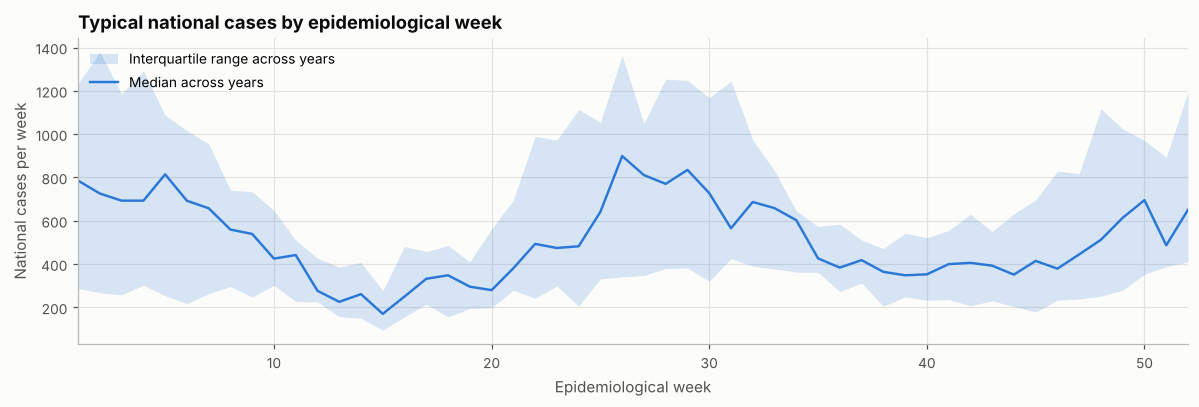

In [7]:
weekly_national = (raw_train.groupby(["year", "week"])[config.CASES_COL].sum()
                   .unstack("year"))
weekly_national = weekly_national.loc[weekly_national.index <= 52]
median_week = weekly_national.median(axis=1)
q25, q75 = weekly_national.quantile(0.25, axis=1), weekly_national.quantile(0.75, axis=1)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(median_week.index, q25, q75, color=viz.BLUE, alpha=0.18, linewidth=0, label="Interquartile range across years")
ax.plot(median_week.index, median_week.values, color=viz.BLUE, label="Median across years")
ax.set_title("Typical national cases by epidemiological week")
ax.set_xlabel("Epidemiological week")
ax.set_ylabel("National cases per week")
ax.set_xlim(1, 52)
ax.legend(loc="upper left")
fig.tight_layout()
viz.save(fig, "eda_a_03_seasonality")
plt.show()

In [8]:
by_monsoon = (raw_train.groupby("monsoon_season")[config.CASES_COL]
              .agg(["mean", "median"])
              .rename(columns={"mean": "mean cases/week", "median": "median cases/week"}))
by_monsoon

,mean cases/week,median cases/week
monsoon_season,,
Inter-monsoon,21.66,6.0
NE Monsoon,33.50,10.0
SW Monsoon,36.08,8.0


**Finding.** Cases follow a clear annual cycle: a main peak during the South-West monsoon (roughly weeks 22 to 34, June to August), a second high period around the North-East monsoon (December to February), and a trough in April and May. The interquartile band is wide, so the size of each season's peak varies a great deal between years even when its timing does not.

**Implication.** `week`, `month` or the monsoon season should be available to the models. Because week 52 sits next to week 1, a cyclical encoding (sine and cosine of the week) is a better choice than the raw week number for Logistic Regression.

## 4. Differences between districts

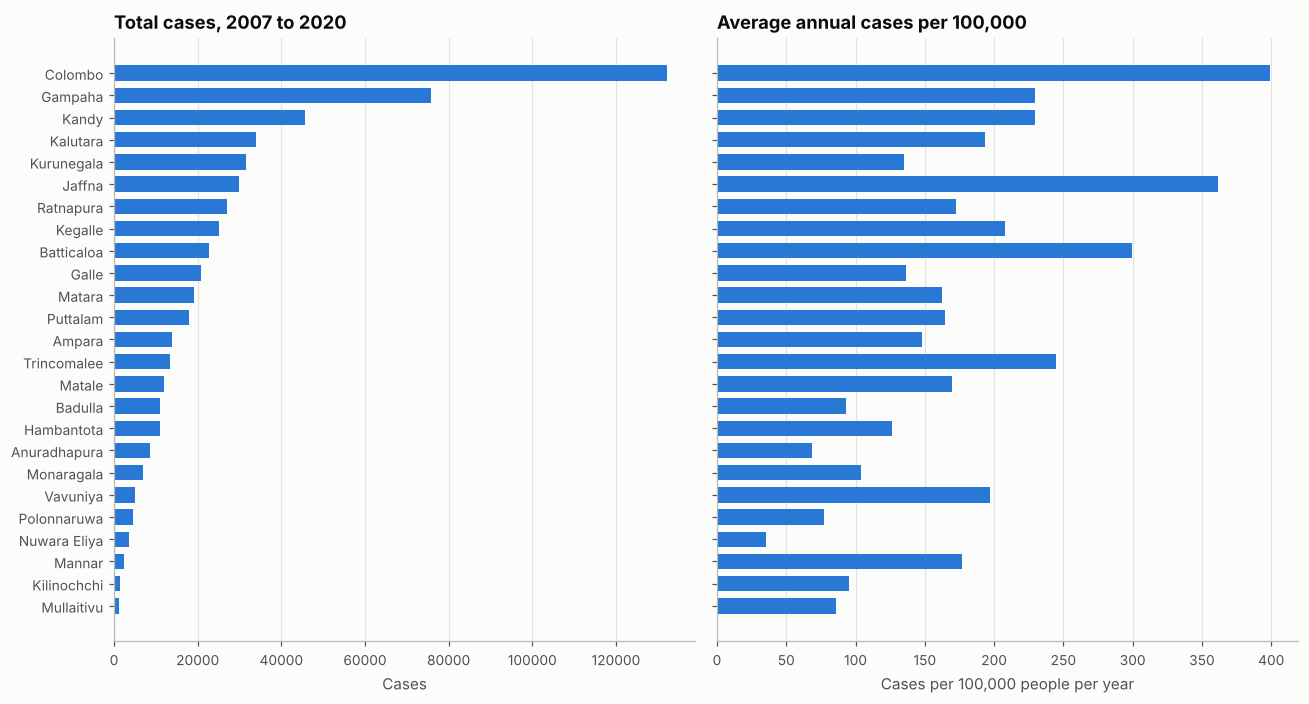

Largest shares: Colombo 22.9%, Gampaha 13.1%


In [9]:
district_totals = raw_train.groupby(config.DISTRICT_COL).agg(
    cases=(config.CASES_COL, "sum"),
    weeks=(config.CASES_COL, "size"),
)
mean_population = raw_train.groupby(config.DISTRICT_COL)["population"].mean()
years_covered = config.TRAIN_YEARS[1] - config.TRAIN_YEARS[0] + 1
district_totals["annual cases per 100,000"] = (
    district_totals["cases"] / years_covered / mean_population * 1e5
)
district_totals["share of national cases (%)"] = 100 * district_totals["cases"] / district_totals["cases"].sum()
district_totals = district_totals.sort_values("cases")

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharey=True)
axes[0].barh(district_totals.index, district_totals["cases"], color=viz.BLUE, height=0.7)
axes[0].set_title("Total cases, 2007 to 2020")
axes[0].set_xlabel("Cases")
axes[0].grid(axis="y", visible=False)

axes[1].barh(district_totals.index, district_totals["annual cases per 100,000"], color=viz.BLUE, height=0.7)
axes[1].set_title("Average annual cases per 100,000")
axes[1].set_xlabel("Cases per 100,000 people per year")
axes[1].grid(axis="y", visible=False)

fig.tight_layout()
viz.save(fig, "eda_a_04_district_burden")
plt.show()

top2 = district_totals["share of national cases (%)"].nlargest(2)
print("Largest shares:", ", ".join(f"{d} {s:.1f}%" for d, s in top2.items()))

**Finding.** Colombo (about 23%) and Gampaha (about 13%) together carry over a third of all training-year cases, largely because they are the most populous districts. Per head of population the ranking changes: Jaffna and Batticaloa sit near the top per 100,000 despite modest totals, while Kurunegala falls well down. Absolute counts and per-capita burden tell different stories.

**Implication.** A single national threshold would label almost every Colombo week an outbreak and almost no Mullaitivu week. This is why the outbreak threshold is fitted **per district**. District identity (or a proxy for it) should also be available to the models.

## 5. Dependence on recent weeks

If this week looks like last week, recent case counts will be the strongest predictors, and a naive "same as before" baseline will be hard to beat.

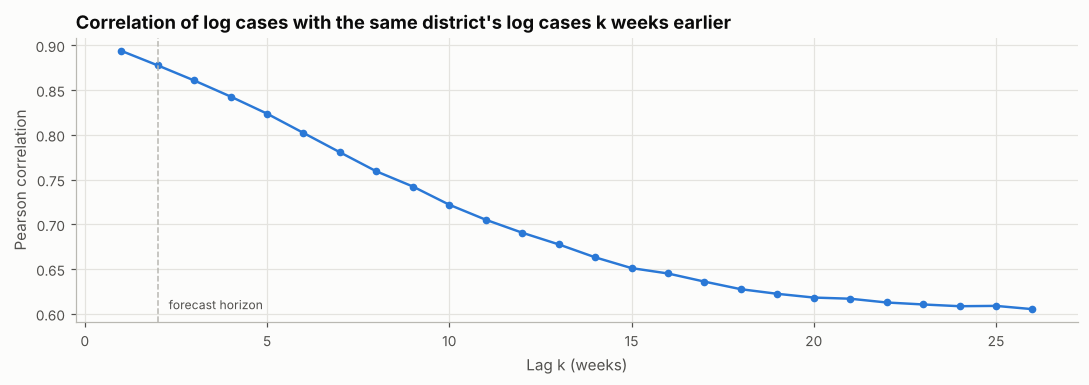

,correlation
1,0.89
2,0.88
4,0.84
8,0.76
13,0.68
26,0.60


In [10]:
log_cases = np.log1p(raw[config.CASES_COL])
train_mask = raw["year"].between(*config.TRAIN_YEARS)
by_district = log_cases.groupby(raw[config.DISTRICT_COL])

lags = range(1, 27)
autocorr = []
for lag in lags:
    lagged = by_district.shift(lag)
    pair = pd.DataFrame({"now": log_cases, "past": lagged})[train_mask].dropna()
    autocorr.append(pair["now"].corr(pair["past"]))
autocorr = pd.Series(autocorr, index=list(lags), name="correlation")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(autocorr.index, autocorr.values, color=viz.BLUE, marker="o", markersize=4)
ax.axvline(config.FORECAST_HORIZON, color=viz.NEUTRAL, linestyle="--", linewidth=1)
ax.text(config.FORECAST_HORIZON + 0.3, autocorr.min(), "forecast horizon", fontsize=8, color=viz.TEXT_MUTED)
ax.set_title("Correlation of log cases with the same district's log cases k weeks earlier")
ax.set_xlabel("Lag k (weeks)")
ax.set_ylabel("Pearson correlation")
fig.tight_layout()
viz.save(fig, "eda_a_05_autocorrelation")
plt.show()

autocorr.loc[[1, 2, 4, 8, 13, 26]].round(3).to_frame()

**Finding.** Case counts are highly persistent: the correlation with the previous week is very high and decays only slowly, staying substantial even half a year back (this partly reflects stable differences in level between districts).

**Implication.** Lagged and rolling case features (for example cases two, three and four weeks earlier, and a four-week rolling mean) should be engineered in preprocessing. A **persistence baseline**, which predicts an outbreak in two weeks whenever there is one now, is the benchmark both models must beat.

## 6. The outbreak label

**Agreed definition.** A district-week is an outbreak when its cases exceed that district's mean plus one standard deviation, with the mean and standard deviation fitted on training years only. The model predicts the label two weeks ahead.

In [11]:
threshold_table = thresholds.sort_values().round(1).to_frame("outbreak threshold (cases/week)")
threshold_table.T

district,Mullaitivu,Kilinochchi,Mannar,Nuwara Eliya,Polonnaruwa,Vavuniya,Monaragala,Anuradhapura,Hambantota,Badulla,...,Galle,Batticaloa,Kegalle,Ratnapura,Kurunegala,Kalutara,Jaffna,Kandy,Gampaha,Colombo
outbreak threshold (cases/week),4.6,6.6,11.4,12.7,16.6,24.3,28.7,31.2,35.7,43.1,...,76.5,83.2,105.4,105.8,113.5,118.8,121.4,172.4,323.2,406.1


In [12]:
split_table = split_summary(df)
split_table

,rows,first_week,last_week,outbreaks,outbreak_rate_%
split,,,,,
train,18200,2006-12-30,2020-12-05,1456,8.0
val,2575,2020-12-26,2022-12-10,77,3.0
test,3825,2022-12-31,2025-11-29,367,9.6


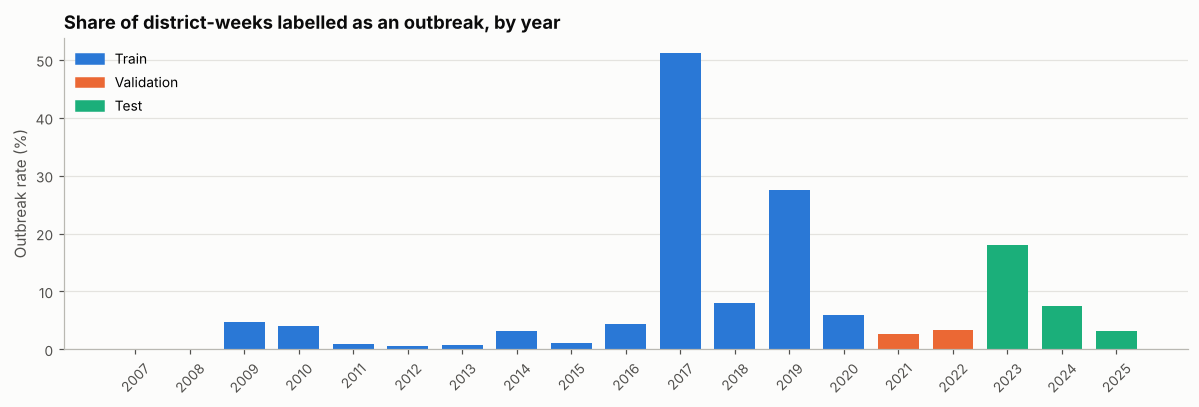

year,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
outbreak rate (%),0.0,0.0,4.8,4.0,0.8,0.5,0.7,3.2,1.1,4.5,51.2,7.9,27.5,5.9,2.6,3.4,18.0,7.5,3.2


In [13]:
by_year = df.groupby("year").agg(rate=("target", "mean"), split=("split", "first"))
colours = by_year["split"].map({"train": viz.BLUE, "val": viz.ORANGE, "test": viz.AQUA})

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(by_year.index, by_year["rate"] * 100, color=colours, width=0.75)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=n) for n, c in
                   [("Train", viz.BLUE), ("Validation", viz.ORANGE), ("Test", viz.AQUA)]],
          loc="upper left")
ax.set_title("Share of district-weeks labelled as an outbreak, by year")
ax.set_ylabel("Outbreak rate (%)")
ax.set_xticks(by_year.index)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
fig.tight_layout()
viz.save(fig, "eda_a_06_outbreak_rate_by_year")
plt.show()

(by_year["rate"] * 100).round(1).to_frame("outbreak rate (%)").T

In [14]:
by_district = (train.groupby(config.DISTRICT_COL)["target"].mean() * 100).sort_values()
print(f"Outbreak rate per district in training years: "
      f"min {by_district.min():.1f}% ({by_district.idxmin()}), "
      f"max {by_district.max():.1f}% ({by_district.idxmax()}), "
      f"median {by_district.median():.1f}%")

Outbreak rate per district in training years: min 4.5% (Trincomalee), max 12.5% (Mullaitivu), median 7.8%


**Finding.** The class is a minority in every split (8.0% train, 3.0% validation, 9.6% test), so **accuracy is not a usable metric**: always predicting "no outbreak" would score above 90%. More importantly, outbreaks are concentrated in time. Roughly half of all district-weeks in 2017 are labelled outbreaks and about a quarter in 2019, while most other training years are below 5%. The **validation years contain only 77 outbreak rows**.

**Implication.**

* Use PR-AUC as the primary metric, with recall, precision, F1 and MCC, as agreed. Use `class_weight="balanced"` or threshold tuning rather than relying on the default 0.5 threshold.
* 77 positives is a small basis for choosing hyperparameters and the decision threshold. Tuning on a single validation block risks choosing settings that suit two quiet years. An expanding-window time-series cross-validation over the training years (for example scikit-learn's `TimeSeriesSplit`) would give more stable choices, with 2021 to 2022 kept as a final check.

## 7. How persistent is the label itself?

In [15]:
def persistence_scores(frame):
    """Precision and recall of predicting target = outbreak_now (no model at all)."""
    predicted, actual = frame["outbreak_now"], frame["target"]
    true_pos = ((predicted == 1) & (actual == 1)).sum()
    return pd.Series({
        "P(outbreak in 2 wks | outbreak now)": actual[predicted == 1].mean(),
        "P(outbreak in 2 wks | no outbreak now)": actual[predicted == 0].mean(),
        "precision": true_pos / predicted.sum(),
        "recall": true_pos / actual.sum(),
    })

persistence = pd.DataFrame({s: persistence_scores(df[df["split"] == s]) for s in ["train", "val"]}).round(3)
persistence

,train,val
P(outbreak in 2 wks | outbreak now),0.71,0.56
P(outbreak in 2 wks | no outbreak now),0.03,0.01
precision,0.71,0.56
recall,0.71,0.56


In [16]:
def episode_lengths(series):
    """Lengths of consecutive runs of 1s in a 0/1 series."""
    run_id = (series != series.shift()).cumsum()
    runs = series.groupby(run_id).agg(["first", "size"])
    return runs.loc[runs["first"] == 1, "size"]

lengths = pd.concat(
    [episode_lengths(g["outbreak_now"]) for _, g in train.groupby(config.DISTRICT_COL)],
    ignore_index=True,
)
print(f"Outbreak episodes in training years: {lengths.size}")
print(f"Median length: {lengths.median():.0f} weeks, mean {lengths.mean():.1f}, longest {lengths.max()} weeks")
print(f"Episodes lasting a single week: {(lengths == 1).mean() * 100:.0f}%")
long_share = lengths[lengths >= 4].sum() / lengths.sum() * 100
print(f"Share of outbreak weeks that belong to episodes of 4+ weeks: {long_share:.0f}%")

Outbreak episodes in training years: 382
Median length: 1 weeks, mean 3.8, longest 40 weeks
Episodes lasting a single week: 56%
Share of outbreak weeks that belong to episodes of 4+ weeks: 73%


**Finding.** Episodes come in two kinds. More than half are single-week blips just over the threshold, but these hold only a small share of outbreak time: roughly three-quarters of all outbreak weeks belong to episodes lasting four weeks or more. Because of those long episodes, knowing that a district is in an outbreak now is highly informative about two weeks later. The persistence rule reaches about 0.71 precision and recall on the training years and 0.56 on validation, while only about 3% of weeks with no current outbreak are followed by one.

**Implication.** This is a strong baseline, and it confirms that the hard and valuable part of the problem is predicting the **start** of an episode, when the persistence rule is always wrong. Performance on episode onsets is therefore reported separately in both model notebooks and in `04b_comparison_analysis.ipynb`.

## 8. Sensitivity to the outbreak definition

The label is a modelling choice, not a given. This section checks how the class balance changes under alternatives. It does **not** change the agreed definition; it informs a group decision.

* **Static, k = 1.0, 1.5, 2.0:** district mean plus k SDs over training years (k = 1.0 is the agreed definition).
* **Rolling 52-week baseline:** a week is an outbreak when cases exceed the mean plus one SD of the same district's previous 52 weeks. This uses only past data, adapts to long-term trends, and is closer to the moving baselines used in epidemiological surveillance.

In [17]:
from src.data_loader import add_outbreak_target, fit_outbreak_thresholds

def prevalence_by_split(target_frame):
    framed = target_frame.copy()
    framed["split"] = year_to_split(framed["year"])
    framed["target_split"] = year_to_split(framed["target_year"])
    keep = framed["target"].notna() & (framed["split"] != "excluded") & (framed["split"] == framed["target_split"])
    return framed[keep].groupby("split")["target"].mean().reindex(["train", "val", "test"]) * 100

sensitivity = {}
for k in [1.0, 1.5, 2.0]:
    labelled = add_outbreak_target(raw, fit_outbreak_thresholds(raw, k=k))
    sensitivity[f"static, k = {k}"] = prevalence_by_split(labelled)

# Rolling baseline built only from each district's previous 52 weeks.
past = raw.groupby(config.DISTRICT_COL)[config.CASES_COL]
rolling_mean = past.transform(lambda s: s.shift(1).rolling(52, min_periods=26).mean())
rolling_std = past.transform(lambda s: s.shift(1).rolling(52, min_periods=26).std())
rolling = raw.copy()
rolling["outbreak_now"] = (rolling[config.CASES_COL] > rolling_mean + rolling_std).astype(float).where(rolling_mean.notna())
by_district_rolling = rolling.groupby(config.DISTRICT_COL)
rolling["target"] = by_district_rolling["outbreak_now"].shift(-config.FORECAST_HORIZON)
rolling["target_year"] = by_district_rolling["year"].shift(-config.FORECAST_HORIZON)
sensitivity["rolling 52-week, k = 1.0"] = prevalence_by_split(rolling)

pd.DataFrame(sensitivity).T.round(1).rename(columns=lambda c: f"{c} outbreak rate (%)")

split,train outbreak rate (%),val outbreak rate (%),test outbreak rate (%)
"static, k = 1.0",8.0,3.0,9.6
"static, k = 1.5",5.3,1.5,5.1
"static, k = 2.0",3.8,0.9,2.5
"rolling 52-week, k = 1.0",19.2,24.7,18.1


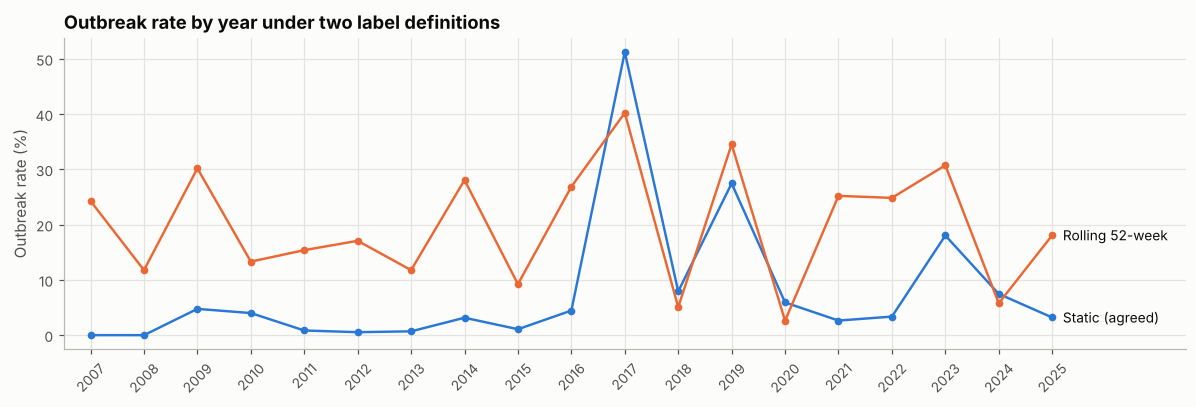

In [18]:
static_by_year = df.groupby("year")["target"].mean() * 100
rolling_valid = rolling[rolling["target"].notna() & rolling["year"].between(config.TRAIN_YEARS[0], config.TEST_YEARS[1])]
rolling_by_year = rolling_valid.groupby("year")["target"].mean() * 100

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(static_by_year.index, static_by_year.values, color=viz.BLUE, marker="o", markersize=4)
ax.plot(rolling_by_year.index, rolling_by_year.values, color=viz.ORANGE, marker="o", markersize=4)
ax.text(static_by_year.index[-1] + 0.2, static_by_year.iloc[-1], "Static (agreed)", color=viz.TEXT, fontsize=9, va="center")
ax.text(rolling_by_year.index[-1] + 0.2, rolling_by_year.iloc[-1], "Rolling 52-week", color=viz.TEXT, fontsize=9, va="center")
ax.set_title("Outbreak rate by year under two label definitions")
ax.set_ylabel("Outbreak rate (%)")
ax.set_xticks(static_by_year.index)
ax.tick_params(axis="x", rotation=45)
ax.set_xlim(static_by_year.index[0] - 0.5, static_by_year.index[-1] + 2.5)
fig.tight_layout()
viz.save(fig, "eda_a_07_label_definitions")
plt.show()

**Finding.** Raising k shrinks the minority class quickly, so k = 1.0 is already the most balanced static option. The rolling baseline behaves very differently: it spreads outbreaks across all years (roughly 18% to 25% in every split) instead of concentrating them in 2017 and 2019, because it asks "is this unusually high **for this district recently**?" rather than "is this high compared with the whole 2007 to 2020 history?".

**What each definition means for the project**

| | Static (agreed) | Rolling 52-week |
|---|---|---|
| Question answered | Is this a historically large outbreak? | Is this an unusual surge for this district right now? |
| Balance across splits | Uneven (validation 3%) | Even (about 20%) |
| Ease of explanation | Simple | Needs more justification |
| Fit with surveillance practice | Weaker | Closer to moving-baseline methods |

This is a decision for the group. Keeping the agreed static label is entirely defensible, provided the small validation set is handled with time-series cross-validation and the concentration in epidemic years is discussed as a limitation.

In [19]:
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
split_table.to_csv(config.METRICS_DIR / "eda_split_summary.csv")
thresholds.round(2).to_csv(config.METRICS_DIR / "outbreak_thresholds.csv")
persistence.to_csv(config.METRICS_DIR / "eda_persistence_baseline.csv")
print("Saved split summary, thresholds and persistence baseline to results/metrics/")

Saved split summary, thresholds and persistence baseline to results/metrics/


## 9. Summary of findings

| # | Finding | Consequence for later steps |
|---|---|---|
| 1 | Weekly cases are extremely right-skewed; log(1 + x) removes most of the skew | Log-transform case-based features for Logistic Regression |
| 2 | A few epidemic years (2017, 2019) dominate; validation years are quiet and test years are busier | Discuss distribution shift between splits in the report |
| 3 | Strong annual seasonality tied to the monsoons | Provide week or season to the models, using a cyclical week encoding |
| 4 | Large differences between districts in absolute and per-capita burden | Per-district thresholds (already in place); give models district information |
| 5 | Cases are highly autocorrelated | Engineer lag and rolling case features; persistence is the baseline to beat |
| 6 | Outbreaks are 8% of training rows, 3% of validation and 9.6% of test | Accuracy is unusable; PR-AUC primary; class weighting or threshold tuning |
| 7 | Only 77 outbreak rows in validation | Prefer expanding-window time-series CV for tuning |
| 8 | Most outbreak time sits in long episodes; persistence alone scores about 0.7 on training years | Report performance on episode onsets separately |
| 9 | The label is sensitive to its definition | **Decided on 12 October:** keep the static label and tune with time-series cross-validation (`02a_preprocessing.ipynb`) |